In [1]:
from pathlib import Path
import json,sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if not (ROOT/'data').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from utils.calculations import calculate_project,calculate_summary,break_even_time_savings,target_time_savings,required_time_multiplier_for_target,fmt
CONFIG=json.loads((ROOT/'data/task_07_efficiency_config.json').read_text(encoding='utf-8'))
frame,summary=calculate_summary(CONFIG)
be=break_even_time_savings(CONFIG)
task_opening=f"""# Экзаменационная задача №{CONFIG['task_id']}. {CONFIG['title']}
**Студент:** {CONFIG['student_name']}  
**Группа:** {CONFIG['group']}  
**Организация:** {CONFIG['organization']}  
**Система:** {CONFIG['system_name']}  
**Горизонт анализа:** {CONFIG['horizon_years']} лет  
**Ставка дисконтирования:** {CONFIG['discount_rate']*100:.0f}% годовых

Все исходные данные загружаются из JSON, а денежные потоки, показатели эффективности, графики и выводы рассчитываются ниже по формулам модели."""
display(Markdown(task_opening))

# Экзаменационная задача №7. Оценка эффективности внедрения информационной системы
**Студент:** Кузнецова Дарья Михайловна  
**Группа:** БИ ОЗФО5-1  
**Организация:** Государственное учреждение  
**Система:** Информационная система для автоматизации документооборота  
**Горизонт анализа:** 5 лет  
**Ставка дисконтирования:** 10% годовых

Все исходные данные загружаются из JSON, а денежные потоки, показатели эффективности, графики и выводы рассчитываются ниже по формулам модели.

## Условие задачи

Государственное учреждение рассматривает внедрение новой информационной системы для автоматизации документооборота. Необходимо оценить экономическую эффективность проекта на пятилетнем горизонте.

**Инвестиции:** разработка и внедрение — 35 млн руб. в год 0; оборудование — 15 млн руб. в год 0; обучение персонала — 5 млн руб. в год 0.

**Ежегодные затраты:** лицензии ПО — 3 млн руб.; техническая поддержка — 2 млн руб.; администрирование — 4 млн руб.

**Ежегодные выгоды:** экономия времени сотрудников — 8 млн руб.; снижение расходов на бумагу и печать — 2 млн руб.; сокращение ошибок — 3 млн руб.; ускорение процессов — 2 млн руб.; рост удовлетворённости граждан — 1 млн руб., но это неденежная выгода.

Дополнительно заданы: горизонт 5 лет, ставка дисконтирования 10%, налог на прибыль 20% и линейная амортизация оборудования за 5 лет.

## Экономическая постановка и методические решения

Оцениваются ROI, NPV, IRR, простой и дисконтированный Payback Period.

Амортизация не является денежным расходом, поэтому она уменьшает налогооблагаемую прибыль, но прибавляется обратно при расчёте денежного потока. Налог на прибыль рассчитывается как 20% от положительной прибыли до налога.

Рост удовлетворённости граждан — полезный социальный эффект, но в условии он не имеет денежной оценки. Поэтому он показывается отдельно и не включается в базовый денежный поток. Если учреждение сможет перевести его в денежный эквивалент, это значение можно добавить в JSON.

`NPV` является основным критерием: при `NPV > 0` проект создаёт стоимость при заданной ставке дисконтирования. ROI дополняет NPV, но сам по себе не учитывает время поступления денег.

## Шаг 1. Исходные данные и инвестиции

Год 0 содержит первоначальные вложения. Годы 1–5 содержат эксплуатационные затраты и финансовые выгоды. Неденежная выгода отображается отдельно.

In [2]:
investment_rows=[{'Компонент':'Разработка и внедрение','Сумма, млн руб.':fmt(CONFIG['investments']['development_and_implementation'])},{'Компонент':'Оборудование','Сумма, млн руб.':fmt(CONFIG['investments']['equipment'])},{'Компонент':'Обучение персонала','Сумма, млн руб.':fmt(CONFIG['investments']['staff_training'])}]
display(pd.DataFrame(investment_rows))
benefit_labels={'staff_time_savings':'Экономия времени сотрудников','paper_and_printing_savings':'Снижение расходов на бумагу и печать','error_reduction':'Сокращение ошибок','process_acceleration':'Ускорение процессов','citizen_satisfaction_non_cash':'Рост удовлетворённости граждан'}
benefit_rows=[]
for name,value in CONFIG['annual_benefits'].items():
    benefit_rows.append({'Выгода':benefit_labels.get(name,name),'Сумма, млн руб./год':fmt(value),'В денежном потоке':('Да' if CONFIG.get('modeling_choices',{}).get('include_non_cash_benefit_in_cash_flow',False) else 'Нет') if name=='citizen_satisfaction_non_cash' else 'Да'})
display(pd.DataFrame(benefit_rows))
print(f"Общий объём инвестиций в год 0: {fmt(summary['investment'])} млн руб.")
print(f"Денежные выгоды, используемые в расчёте: {fmt(frame['benefits'].iloc[1])} млн руб./год.")
print('Статус денежной оценки удовлетворённости граждан: ' + ('включена в денежный поток' if CONFIG.get('modeling_choices',{}).get('include_non_cash_benefit_in_cash_flow',False) else 'показывается отдельно и исключена из денежного потока'))

,Компонент,"Сумма, млн руб."
0,Разработка и внедрение,"35,00"
1,Оборудование,"15,00"
2,Обучение персонала,"5,00"


,Выгода,"Сумма, млн руб./год",В денежном потоке
0,Экономия времени сотрудников,"8,00",Да
1,Снижение расходов на бумагу и печать,"2,00",Да
2,Сокращение ошибок,"3,00",Да
3,Ускорение процессов,"2,00",Да
4,Рост удовлетворённости граждан,"1,00",Нет


Общий объём инвестиций в год 0: 55,00 млн руб.
Денежные выгоды, используемые в расчёте: 15,00 млн руб./год.
Статус денежной оценки удовлетворённости граждан: показывается отдельно и исключена из денежного потока


## Шаг 2. Денежные потоки и налог

Годовая прибыль до налога = денежные выгоды − эксплуатационные затраты − амортизация.

Налог = прибыль до налога × ставка налога.

Чистый денежный поток = прибыль после налога + амортизация.

Амортизация возвращается в поток, поскольку она уменьшает налогооблагаемую прибыль, но не требует выплаты денег.

In [3]:
cash=frame[['year','benefits','operating_costs','depreciation','taxable_profit','profit_tax','net_profit','cash_flow']].copy()
cash.columns=['Год','Денежные выгоды','Эксплуатационные затраты','Амортизация','Прибыль до налога','Налог','Прибыль после налога','Чистый денежный поток']
for col in cash.columns[1:]: cash[col]=cash[col].map(lambda x:fmt(x,2))
display(cash)
print(f"Ежегодный положительный чистый поток после внедрения: {fmt(frame.loc[1,'cash_flow'])} млн руб.")
print(f"Суммарный номинальный поток за весь горизонт с учётом инвестиций: {fmt(frame['cash_flow'].sum())} млн руб.")

,Год,Денежные выгоды,Эксплуатационные затраты,Амортизация,Прибыль до налога,Налог,Прибыль после налога,Чистый денежный поток
0,0,"0,00","0,00","0,00","0,00","0,00","0,00","-55,00"
1,1,"15,00","9,00","3,00","3,00","0,60","2,40","5,40"
2,2,"15,00","9,00","3,00","3,00","0,60","2,40","5,40"
3,3,"15,00","9,00","3,00","3,00","0,60","2,40","5,40"
4,4,"15,00","9,00","3,00","3,00","0,60","2,40","5,40"
5,5,"15,00","9,00","3,00","3,00","0,60","2,40","5,40"


Ежегодный положительный чистый поток после внедрения: 5,40 млн руб.
Суммарный номинальный поток за весь горизонт с учётом инвестиций: -28,00 млн руб.


## Шаг 3. NPV

Каждый денежный поток приводится к моменту начала проекта: `PV_t = CF_t/(1+r)^t`. Инвестиции года 0 входят в NPV полностью со знаком минус.

In [4]:
pv=frame[['year','cash_flow','discount_factor','pv','cumulative_pv']].copy()
pv.columns=['Год','CF','Дисконтирующий коэффициент','PV потока','Накопленный PV']
for col in ['CF','Дисконтирующий коэффициент','PV потока','Накопленный PV']: pv[col]=pv[col].map(lambda x:fmt(x,3))
display(pv)
print(f"NPV проекта: {fmt(summary['npv'])} млн руб.")
print('Интерпретация: проект создаёт стоимость.' if summary['npv']>0 else 'Интерпретация: проект не создаёт стоимость при заданной ставке дисконтирования.')

,Год,CF,Дисконтирующий коэффициент,PV потока,Накопленный PV
0,0,"-55,000","1,000","-55,000","-55,000"
1,1,"5,400","0,909","4,909","-50,091"
2,2,"5,400","0,826","4,463","-45,628"
3,3,"5,400","0,751","4,057","-41,571"
4,4,"5,400","0,683","3,688","-37,883"
5,5,"5,400","0,621","3,353","-34,530"


NPV проекта: -34,53 млн руб.
Интерпретация: проект не создаёт стоимость при заданной ставке дисконтирования.


## Шаг 4. IRR и Payback Period

IRR — ставка, при которой NPV равен нулю. Она рассчитывается численным методом бисекции. Если даже при ставке 0% проект не возвращает инвестиции, IRR будет отрицательной.

Простой Payback не дисконтирует потоки. Дисконтированный Payback использует накопленный PV. Если накопление не становится неотрицательным за горизонт, срок окупаемости не достигается.

In [5]:
metrics=pd.DataFrame({'Показатель':['IRR','Простой Payback','Дисконтированный Payback','ROI','NPV'],'Результат':[f"{fmt(summary['irr']*100,2)}%" if summary['irr'] is not None else 'не рассчитывается',f"{fmt(summary['payback'],2)} лет" if summary['payback'] is not None else 'не достигается',f"{fmt(summary['discounted_payback'],2)} лет" if summary['discounted_payback'] is not None else 'не достигается',f"{fmt((summary['net_nominal']/summary['costs'])*100,2)}%",f"{fmt(summary['npv'])} млн руб."]})
display(metrics)
print('Что видно из показателей:')
print(f"• ROI рассчитывается по номинальным суммарным выгодам и затратам: {fmt((summary['net_nominal']/summary['costs'])*100,2)}%.")
print(f"• IRR: {fmt(summary['irr']*100,2)}%, то есть ниже требуемой ставки {CONFIG['discount_rate']*100:.0f}%." if summary['irr'] is not None else '• IRR не определяется на заданном диапазоне ставок.')
print('• Проект окупается на заданном горизонте.' if summary['payback'] is not None else '• Проект не окупается на заданном пятилетнем горизонте.')

,Показатель,Результат
0,IRR,"-19,83%"
1,Простой Payback,не достигается
2,Дисконтированный Payback,не достигается
3,ROI,"-25,00%"
4,NPV,"-34,53 млн руб."


Что видно из показателей:
• ROI рассчитывается по номинальным суммарным выгодам и затратам: -25,00%.
• IRR: -19,83%, то есть ниже требуемой ставки 10%.
• Проект не окупается на заданном пятилетнем горизонте.


## Шаг 5. График накопленного денежного потока и PV

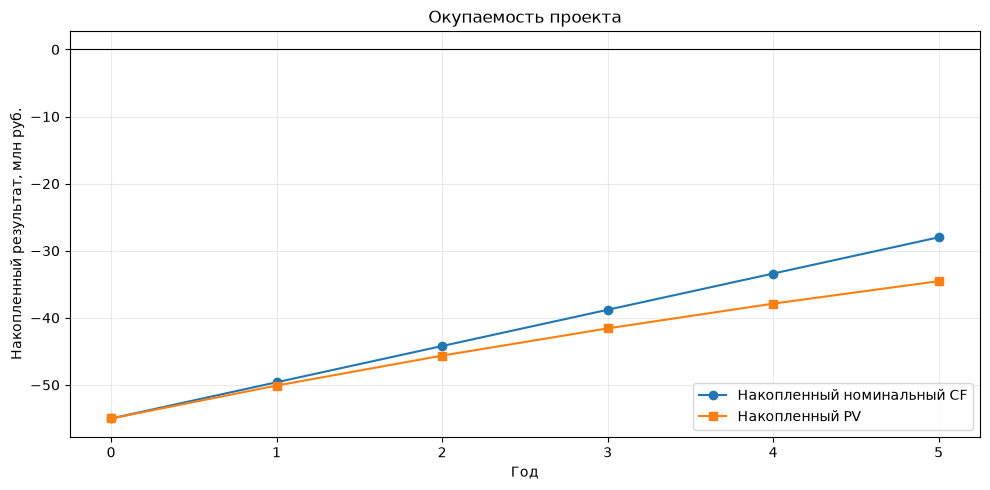

Что видно из графика:
• Накопленный номинальный результат к концу горизонта: -28,00 млн руб.
• Накопленный дисконтированный результат к концу горизонта: -34,53 млн руб.
• Ни одна линия не достигает нуля: проект не окупается на заданном горизонте.


In [6]:
plt.figure(figsize=(10,5))
plt.plot(frame['year'],frame['cumulative_cf'],marker='o',label='Накопленный номинальный CF')
plt.plot(frame['year'],frame['cumulative_pv'],marker='s',label='Накопленный PV')
plt.axhline(0,color='black',linewidth=.8)
plt.xlabel('Год');plt.ylabel('Накопленный результат, млн руб.');plt.title('Окупаемость проекта');plt.grid(alpha=.25);plt.legend();plt.tight_layout();plt.show()
print('Что видно из графика:')
print(f"• Накопленный номинальный результат к концу горизонта: {fmt(frame['cumulative_cf'].iloc[-1])} млн руб.")
print(f"• Накопленный дисконтированный результат к концу горизонта: {fmt(frame['cumulative_pv'].iloc[-1])} млн руб.")
print('• Ни одна линия не достигает нуля: проект не окупается на заданном горизонте.' if frame['cumulative_cf'].iloc[-1]<0 else '• Номинальный денежный поток достигает нулевой отметки на горизонте.')

## Шаг 6. Анализ чувствительности NPV

In [7]:
rate_rows=[]
for rate in CONFIG['sensitivity']['discount_rates']:
    _,s=calculate_summary(CONFIG,discount_rate=rate);rate_rows.append({'Ставка':f"{rate*100:.0f}%",'NPV, млн руб.':s['npv'],'Вывод':'Эффективен' if s['npv']>0 else 'Неэффективен'})
rate_df=pd.DataFrame(rate_rows);rate_df['NPV, млн руб.']=rate_df['NPV, млн руб.'].map(lambda x:fmt(x));display(rate_df)
time_rows=[]
for mult in CONFIG['sensitivity']['time_savings_multipliers']:
    f,s=calculate_summary(CONFIG,time_multiplier=mult);time_rows.append({'Изменение экономии времени':f"{(mult-1)*100:+.0f}%",'Годовые денежные выгоды, млн руб.':f['benefits'].iloc[1],'NPV, млн руб.':s['npv'],'Вывод':'Эффективен' if s['npv']>0 else 'Неэффективен'})
time_df=pd.DataFrame(time_rows);
for col in ['Годовые денежные выгоды, млн руб.','NPV, млн руб.']: time_df[col]=time_df[col].map(lambda x:fmt(x));display(time_df)
dev_rows=[]
for mult in CONFIG['sensitivity']['development_cost_multipliers']:
    f,s=calculate_summary(CONFIG,development_multiplier=mult);dev_rows.append({'Изменение стоимости разработки':f"{(mult-1)*100:+.0f}%",'Инвестиции, млн руб.':s['investment'],'NPV, млн руб.':s['npv'],'Вывод':'Эффективен' if s['npv']>0 else 'Неэффективен'})
dev_df=pd.DataFrame(dev_rows);
for col in ['Инвестиции, млн руб.','NPV, млн руб.']: dev_df[col]=dev_df[col].map(lambda x:fmt(x));display(dev_df)
print('Что видно из анализа чувствительности:')
print('• При всех проверенных ставках дисконтирования проект остаётся неэффективным.' if all(x['NPV, млн руб.']<0 for x in rate_rows) else '• При изменении ставки дисконтирования статус проекта меняется.')
print('• Изменение экономии времени влияет на NPV, но в заданном диапазоне не меняет вывод.' if all(x['NPV, млн руб.']<0 for x in time_rows) else '• Экономия времени может изменить статус проекта.')
print('• Снижение стоимости разработки улучшает NPV, но в заданном диапазоне не делает проект эффективным.' if all(x['NPV, млн руб.']<0 for x in dev_rows) else '• Стоимость разработки является пороговым фактором.')

,Ставка,"NPV, млн руб.",Вывод
0,8%,"-33,44",Неэффективен
1,10%,"-34,53",Неэффективен
2,14%,"-36,46",Неэффективен


,Изменение экономии времени,"Годовые денежные выгоды, млн руб.","NPV, млн руб.",Вывод
0,-20%,"13,40",-39.381959,Неэффективен
1,+0%,"15,00",-34.529751,Неэффективен
2,+20%,"16,60",-29.677544,Неэффективен


,Изменение экономии времени,"Годовые денежные выгоды, млн руб.","NPV, млн руб.",Вывод
0,-20%,"13,40","-39,38",Неэффективен
1,+0%,"15,00","-34,53",Неэффективен
2,+20%,"16,60","-29,68",Неэффективен


,Изменение стоимости разработки,"Инвестиции, млн руб.","NPV, млн руб.",Вывод
0,-20%,"48,00",-27.529751,Неэффективен
1,+0%,"55,00",-34.529751,Неэффективен
2,+20%,"62,00",-41.529751,Неэффективен


,Изменение стоимости разработки,"Инвестиции, млн руб.","NPV, млн руб.",Вывод
0,-20%,"48,00","-27,53",Неэффективен
1,+0%,"55,00","-34,53",Неэффективен
2,+20%,"62,00","-41,53",Неэффективен


Что видно из анализа чувствительности:
• При всех проверенных ставках дисконтирования проект остаётся неэффективным.
• Изменение экономии времени влияет на NPV, но в заданном диапазоне не меняет вывод.
• Снижение стоимости разработки улучшает NPV, но в заданном диапазоне не делает проект эффективным.


## Шаг 7. Порог безубыточности и стратегические выводы

In [8]:
print(f"Для NPV = 0 требуется ежегодная денежная выгода примерно {fmt(be['required_annual_monetary_benefits'])} млн руб.")
print(f"При прочих неизменных параметрах минимальная экономия времени должна составлять около {fmt(be['required_time_savings'])} млн руб./год.")
print(f"Это примерно на {fmt(be['increase_percent']*100,1)}% выше текущего значения экономии времени {fmt(be['current_time_savings'])} млн руб./год.")
print('Рекомендация: не утверждать проект в текущем виде как экономически эффективный; сначала снизить инвестиции, увеличить подтверждённые денежные выгоды или реализовать поэтапное внедрение.')

Для NPV = 0 требуется ежегодная денежная выгода примерно 26,39 млн руб.
При прочих неизменных параметрах минимальная экономия времени должна составлять около 19,39 млн руб./год.
Это примерно на 142,3% выше текущего значения экономии времени 8,00 млн руб./год.
Рекомендация: не утверждать проект в текущем виде как экономически эффективный; сначала снизить инвестиции, увеличить подтверждённые денежные выгоды или реализовать поэтапное внедрение.


## Итоговый вывод

При текущих денежных параметрах проект не создаёт экономическую стоимость. Неденежная выгода для граждан важна стратегически, но без обоснованной денежной оценки не должна маскировать отрицательные NPV и ROI. Перед принятием решения следует проверить фактическую экономию времени пилотом, пересмотреть масштаб внедрения, рассмотреть поэтапное финансирование и сравнить проект с альтернативами.

## Сценарии выхода в безубыточность и прибыль: подробный экономический анализ

Текущий результат показывает, что проект пока не окупает первоначальные вложения. Чтобы понять, что именно нужно изменить, ниже рассматриваются два уровня анализа:

1. **Однорычаговый анализ** — меняется только один параметр, остальные остаются такими же, как в исходной задаче. Так видно, какой эффект даёт каждый отдельный управленческий рычаг.
2. **Комбинированный анализ** — одновременно меняются несколько параметров. Это более реалистичный план: например, часть затрат удаётся сократить, а оставшийся разрыв закрывается повышением фактической экономии времени сотрудников.

Все параметры диапазонов и комбинированного плана хранятся в JSON в блоке `scenario_analysis`. Целевые значения NPV хранятся в `analysis_targets`.

,Изменение только одного фактора,Новый показатель,Множитель,"NPV, млн руб.","Изменение NPV, млн руб."
0,увеличить экономию времени на 20%,Экономия времени сотрудников,"1,20","-29,68","4,85"
1,сократить ежегодные затраты на 20%,Ежегодные эксплуатационные затраты,"0,80","-29,07","5,46"
2,сократить первоначальные затраты на 20%,Разработка и внедрение,"0,80","-27,53","7,00"
3,увеличить прочие выгоды на 20%,Прочие денежные выгоды,"1,20","-30,28","4,25"


Как читать таблицу: например, если сократить ежегодные эксплуатационные затраты на 20%, меняется только эта статья; инвестиции, выгоды, налог и ставка остаются прежними.


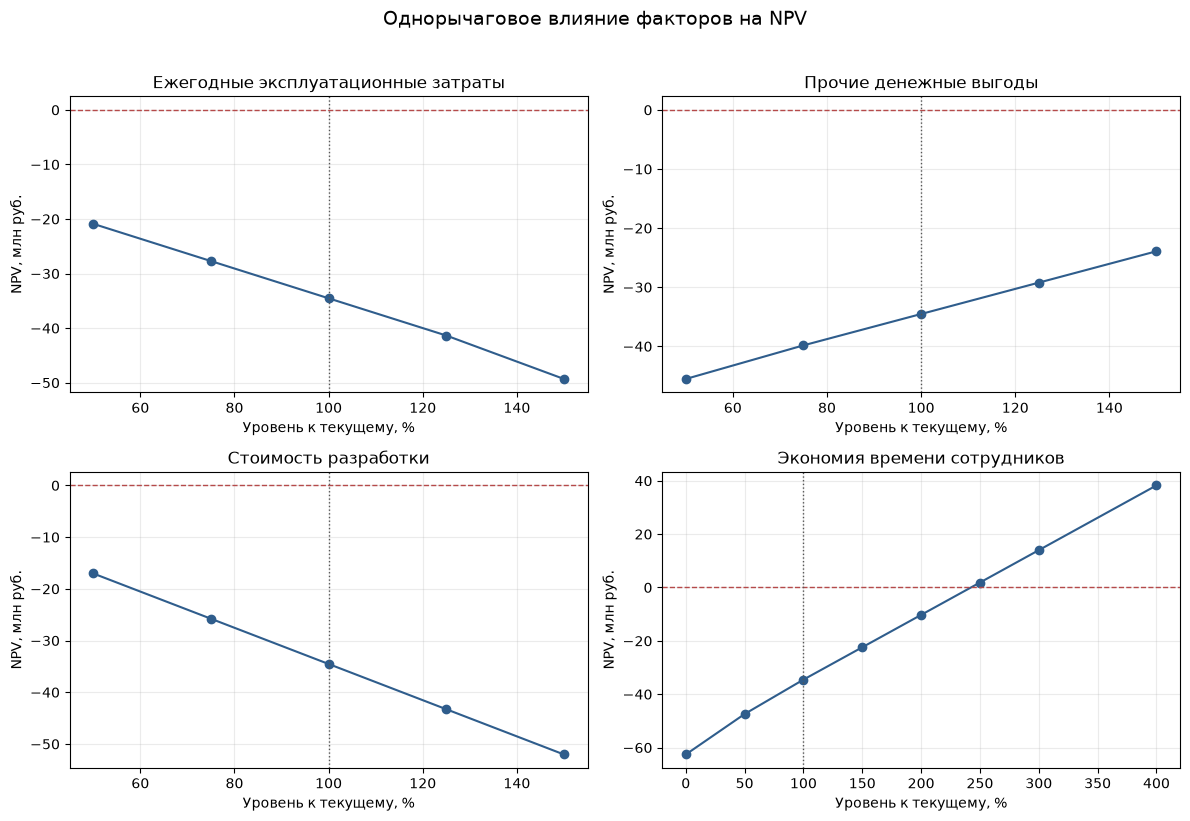

Интерпретация графиков: точка 100% — текущий уровень. Если линия выше нуля, проект создаёт стоимость при таком изменении. Наклон линии показывает, какой фактор сильнее влияет на результат.


,Сценарий,"Целевой NPV, млн руб.","Разработка к текущей, %","Эксплуатационные затраты к текущим, %","Экономия времени к текущей, %","Экономия времени, млн руб./год","Проверочный NPV, млн руб."
0,NPV = 0,"0,00","80,00","80,00","190,97","15,28","0,00"
1,NPV = прибыль,"10,00","80,00","80,00","232,19","18,58","10,00"


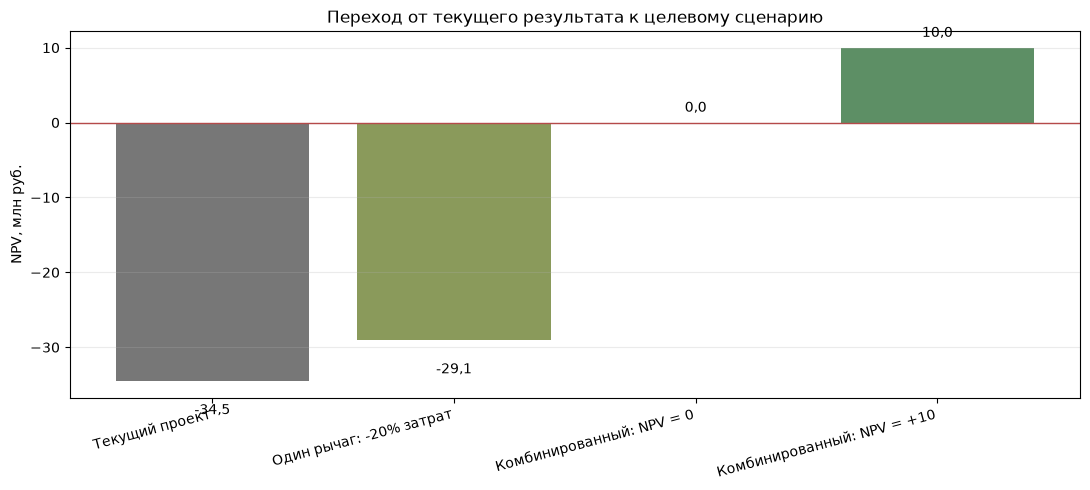

Пошаговая интерпретация комбинированного плана:
1. Стоимость разработки уменьшается до 80% от текущей, а ежегодные эксплуатационные затраты — до 80%.
2. После этих сокращений для NPV = 0 требуется экономия времени 15.28 млн руб./год.
3. Для целевого NPV = +10.00 млн руб. требуется экономия времени 18.58 млн руб./год.
4. Это не единственное решение. Если сократить затраты невозможно, тот же дефицит можно закрывать увеличением денежных выгод; если экономию времени нельзя увеличить, нужно сильнее снижать инвестиции/расходы или обосновывать денежный эквивалент неденежной выгоды.


In [9]:
scenario=CONFIG['scenario_analysis']
targets=CONFIG['analysis_targets']
base_npv=summary['npv']
change=scenario['one_lever_change']

# 1. Понятная таблица: что произойдёт при изменении только одного фактора на 20%.
one_lever_specs=[
    ('Экономия времени сотрудников','time_multiplier',1+change,'увеличить экономию времени'),
    ('Ежегодные эксплуатационные затраты','annual_cost_multiplier',1-change,'сократить ежегодные затраты'),
    ('Разработка и внедрение','development_multiplier',1-change,'сократить первоначальные затраты'),
    ('Прочие денежные выгоды','fixed_benefit_multiplier',1+change,'увеличить прочие выгоды')
]
one_rows=[]
for label,key,mult,action in one_lever_specs:
    kwargs={key:mult}
    _,res=calculate_summary(CONFIG,**kwargs)
    one_rows.append({'Изменение только одного фактора':f'{action} на {change*100:.0f}%', 'Новый показатель':label, 'Множитель':fmt(mult,2), 'NPV, млн руб.':res['npv'], 'Изменение NPV, млн руб.':res['npv']-base_npv})
one_table=pd.DataFrame(one_rows)
for col in ['NPV, млн руб.','Изменение NPV, млн руб.']: one_table[col]=one_table[col].map(lambda x:fmt(x,2))
display(one_table)
print('Как читать таблицу: например, если сократить ежегодные эксплуатационные затраты на 20%, меняется только эта статья; инвестиции, выгоды, налог и ставка остаются прежними.')

# 2. Диапазоны однорычагового анализа для графиков.
lever_ranges={
 'Экономия времени сотрудников':('time_multiplier',scenario['time_savings_multipliers']),
 'Стоимость разработки':('development_multiplier',scenario['development_cost_multipliers']),
 'Ежегодные эксплуатационные затраты':('annual_cost_multiplier',scenario['annual_cost_multipliers']),
 'Прочие денежные выгоды':('fixed_benefit_multiplier',scenario['other_benefits_multipliers'])
}
range_frames=[]
for label,(key,values) in lever_ranges.items():
    rows=[]
    for mult in values:
        _,res=calculate_summary(CONFIG,**{key:mult})
        rows.append({'Фактор':label,'Множитель':mult,'NPV':res['npv']})
    range_frames.append(pd.DataFrame(rows))
range_table=pd.concat(range_frames,ignore_index=True)

fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,(label,group) in zip(axes.ravel(),range_table.groupby('Фактор')):
    ax.plot(group['Множитель']*100,group['NPV'],marker='o',color='#2f5d8c')
    ax.axhline(0,color='#b54a4a',linewidth=1,linestyle='--',label='NPV = 0')
    ax.axvline(100,color='#555555',linewidth=1,linestyle=':',label='Текущий уровень')
    ax.set_title(label); ax.set_xlabel('Уровень к текущему, %'); ax.set_ylabel('NPV, млн руб.'); ax.grid(alpha=.25)
plt.suptitle('Однорычаговое влияние факторов на NPV',y=1.02,fontsize=14)
plt.tight_layout(); plt.show()

print('Интерпретация графиков: точка 100% — текущий уровень. Если линия выше нуля, проект создаёт стоимость при таком изменении. Наклон линии показывает, какой фактор сильнее влияет на результат.')

# 3. Комбинированный план: заданные сокращения затрат + расчёт недостающей экономии времени.
cp=scenario['combined_plan']
combined_zero=required_time_multiplier_for_target(CONFIG,targets['npv_zero_rub_mln'],cp['development_multiplier'],cp['annual_cost_multiplier'],cp['other_benefits_multiplier'])
combined_profit=required_time_multiplier_for_target(CONFIG,targets['npv_profit_rub_mln'],cp['development_multiplier'],cp['annual_cost_multiplier'],cp['other_benefits_multiplier'])
combined_rows=[]
for name,target,solution in [('NPV = 0',targets['npv_zero_rub_mln'],combined_zero),('NPV = прибыль',targets['npv_profit_rub_mln'],combined_profit)]:
    tm=solution['time_multiplier']
    _,res=calculate_summary(CONFIG,time_multiplier=tm,development_multiplier=cp['development_multiplier'],annual_cost_multiplier=cp['annual_cost_multiplier'],fixed_benefit_multiplier=cp['other_benefits_multiplier'])
    combined_rows.append({'Сценарий':name,'Целевой NPV, млн руб.':target,'Разработка к текущей, %':cp['development_multiplier']*100,'Эксплуатационные затраты к текущим, %':cp['annual_cost_multiplier']*100,'Экономия времени к текущей, %':tm*100,'Экономия времени, млн руб./год':CONFIG['annual_benefits']['staff_time_savings']*tm,'Проверочный NPV, млн руб.':res['npv']})
combined_table=pd.DataFrame(combined_rows)
for col in combined_table.columns[1:]: combined_table[col]=combined_table[col].map(lambda x:fmt(x,2))
display(combined_table)

# 4. График сравнения: текущий результат, однорычаговый пример и комбинированные цели.
chart_rows=[{'Сценарий':'Текущий проект','NPV':base_npv},
 {'Сценарий':f'Один рычаг: -{change*100:.0f}% затрат','NPV':one_rows[1]['Изменение NPV, млн руб.']+base_npv},
 {'Сценарий':'Комбинированный: NPV = 0','NPV':targets['npv_zero_rub_mln']},
 {'Сценарий':f'Комбинированный: NPV = +{targets["npv_profit_rub_mln"]:.0f}','NPV':targets['npv_profit_rub_mln']} ]
chart_df=pd.DataFrame(chart_rows)
plt.figure(figsize=(11,5)); bars=plt.bar(chart_df['Сценарий'],chart_df['NPV'],color=['#777777','#8a9a5b','#2f5d8c','#5d8f65'])
plt.axhline(0,color='#b54a4a',linewidth=1); plt.ylabel('NPV, млн руб.'); plt.title('Переход от текущего результата к целевому сценарию'); plt.xticks(rotation=15,ha='right'); plt.grid(axis='y',alpha=.25)
for bar,val in zip(bars,chart_df['NPV']): plt.text(bar.get_x()+bar.get_width()/2, val+(1 if val>=0 else -3), fmt(val,1),ha='center',va='bottom' if val>=0 else 'top')
plt.tight_layout(); plt.show()

print('Пошаговая интерпретация комбинированного плана:')
print(f"1. Стоимость разработки уменьшается до {cp['development_multiplier']*100:.0f}% от текущей, а ежегодные эксплуатационные затраты — до {cp['annual_cost_multiplier']*100:.0f}%.")
print(f"2. После этих сокращений для NPV = 0 требуется экономия времени {CONFIG['annual_benefits']['staff_time_savings']*combined_zero['time_multiplier']:.2f} млн руб./год.")
print(f"3. Для целевого NPV = +{targets['npv_profit_rub_mln']:.2f} млн руб. требуется экономия времени {CONFIG['annual_benefits']['staff_time_savings']*combined_profit['time_multiplier']:.2f} млн руб./год.")
print('4. Это не единственное решение. Если сократить затраты невозможно, тот же дефицит можно закрывать увеличением денежных выгод; если экономию времени нельзя увеличить, нужно сильнее снижать инвестиции/расходы или обосновывать денежный эквивалент неденежной выгоды.')

In [10]:
%%capture
# Экспорт выполненного Notebook в HTML-отчёт
!python -m jupyter nbconvert --to html --no-input --output-dir ../reports --output task_07_report task_07_efficiency.ipynb